# Lab 3: select, explain, then test

**Goal.** Compare ridge, random forests, gradient boosting and support vector regression on the same solubility problem. Evaluate the entire family-and-hyperparameter selection procedure with nested cross-validation, interpret development behaviour, then freeze a candidate before opening the final test.

Run top to bottom. In the student notebook, complete each `# TODO` using the requested object names. The checks verify useful invariants, not a particular winning algorithm. The search uses a modest CPU budget; no GPU is needed. Record the search space before viewing results.

**Deliverables:** outer-fold results against a baseline, a development importance plot, one final test comparison and parity plot, and a qualified scientific recommendation. Budget 90–120 minutes for the tasks and reflection.

In [1]:
# Setup: detect Colab and install missing core packages there.
import importlib.util
import subprocess
import sys
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'sklearn': 'scikit-learn', 'threadpoolctl': 'threadpoolctl'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing and IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
if missing and not IN_COLAB:
    raise RuntimeError('Install the course requirements before running this notebook.')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from threadpoolctl import threadpool_limits
print(f'Python {sys.version.split()[0]} | sklearn {sklearn.__version__} | Colab: {IN_COLAB}')

Python 3.12.14 | sklearn 1.9.1 | Colab: False


## Load the data

The ESOL file is downloaded rather than redistributed. This loader first checks local paths, then tries the canonical download and its DeepChem GitHub mirror and verifies the same SHA-256 as `data/README.md`. The five descriptors and target units match Lab 2. Keeping the representation fixed makes the algorithm comparison interpretable.

In [2]:
# Load a verified ESOL copy locally, then try the canonical and mirrored downloads.
from pathlib import Path
from urllib.request import urlopen
from urllib.error import URLError
from io import BytesIO
import hashlib
candidates = [Path('data/esol.csv'), Path('../../../data/esol.csv')]
local = next((p for p in candidates if p.exists()), None)
urls = ['https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv',
        'https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv']
raw = local.read_bytes() if local is not None else None
if raw is None:
    for url in urls:
        try:
            with urlopen(url, timeout=30) as response:
                raw = response.read()
            break
        except (URLError, TimeoutError):
            continue
if raw is None:
    raise RuntimeError('Could not download ESOL; check your connection or run scripts/fetch_data.py.')
expected = '8c06a76f0c6487d29ab0f903e6a7a7139f189ab3c1178f159c8be8964602f189'
assert hashlib.sha256(raw).hexdigest() == expected, 'ESOL checksum differs; inspect the source.'
esol = pd.read_csv(BytesIO(raw))
print(f'Loaded {len(esol)} molecules.')
esol.head(3)

Loaded 1128 molecules.


,Compound ID,ESOL predicted log solubility in mols per litre,Minimum Degree,Molecular Weight,Number of H-Bond Donors,Number of Rings,Number of Rotatable Bonds,Polar Surface Area,measured log solubility in mols per litre,smiles
0,Amigdalin,-0.974,1,457.432,7,3,7,202.32,-0.77,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...
1,Fenfuram,-2.885,1,201.225,1,2,2,42.24,-3.30,Cc1occc1C(=O)Nc2ccccc2
2,citral,-2.579,1,152.237,0,0,4,17.07,-2.06,CC(C)=CCCC(C)=CC(=O)


## Task 1 — Declare the experiment and reserve the test

Create `features`, `X` and `y` with the five descriptors used in Chapter 2. Make an 80/20 split with `random_state=42`, naming the parts `X_dev`, `X_test`, `y_dev`, `y_test`. The metric is RMSE in log10(mol/L). The final test remains closed until Task 7.

Write down the limitation now: a random molecular split allows related chemistry across partitions and does not estimate performance on genuinely new scaffolds. The repeated teaching split is familiar to course readers; a research claim needs fresh independent evidence.

In [3]:
# Task 1: define the representation and reserve the final test.
from sklearn.model_selection import train_test_split
features = ['Molecular Weight', 'Number of H-Bond Donors', 'Number of Rings',
            'Number of Rotatable Bonds', 'Polar Surface Area']
X = esol[features]
y = esol['measured log solubility in mols per litre']
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Development: {len(X_dev)}; final test: {len(X_test)}')

Development: 902; final test: 226


In [4]:
assert list(X.columns) == features and len(features) == 5, 'Use the declared five descriptors.'
assert set(X_dev.index).isdisjoint(X_test.index), 'Partitions must not overlap.'
assert len(X_dev) + len(X_test) == len(X), 'Account for every row.'
assert y_dev.index.equals(X_dev.index), 'Keep feature and target rows aligned.'
print('Check passed: representation and split.')

Check passed: representation and split.


## Task 2 — Define one search across families and settings

Build `pipeline` with named steps `scale` and `model`. Build a list of four dictionaries called `grids`. Each dictionary replaces the model with one family and supplies only its valid parameters. Use scaling for ridge and SVR, and `"passthrough"` for tree models.

Use two ridge alphas (1, 100), two forest leaf sizes (2, 8; 60 trees), two boosting learning rates (0.05, 0.1; 80 iterations), and four SVR combinations (C 1 or 10; gamma 0.03 or 0.3). This is ten configurations. `inner` and `outer` are shuffled three-fold KFold objects with fixed seeds; `search` is a GridSearchCV with negative RMSE and `n_jobs=1`. Set boosting early stopping off so iteration count is explicit.

In [5]:
# Task 2a: define the pipeline and modest candidate grid.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
pipeline = Pipeline([('scale', StandardScaler()), ('model', Ridge())])
grids = [
    {'scale': [StandardScaler()], 'model': [Ridge()], 'model__alpha': [1, 100]},
    {'scale': ['passthrough'],
     'model': [RandomForestRegressor(n_estimators=60, max_features=0.8, random_state=42, n_jobs=1)],
     'model__min_samples_leaf': [2, 8]},
    {'scale': ['passthrough'],
     'model': [HistGradientBoostingRegressor(max_iter=80, max_leaf_nodes=15,
              early_stopping=False, random_state=42)], 'model__learning_rate': [0.05, 0.1]},
    {'scale': [StandardScaler()], 'model': [SVR(epsilon=0.1)],
     'model__C': [1, 10], 'model__gamma': [0.03, 0.3]},
]
print('Model families:', [type(g['model'][0]).__name__ for g in grids])

Model families: ['Ridge', 'RandomForestRegressor', 'HistGradientBoostingRegressor', 'SVR']


In [6]:
# Task 2b: define the nested evaluation before looking at results.
from sklearn.model_selection import GridSearchCV, KFold, ParameterGrid
inner = KFold(n_splits=3, shuffle=True, random_state=42)
outer = KFold(n_splits=3, shuffle=True, random_state=42)
outer_splits = list(outer.split(X_dev, y_dev))
search = GridSearchCV(pipeline, grids, cv=inner,
                      scoring='neg_root_mean_squared_error', n_jobs=1)
print(f'{len(ParameterGrid(grids))} configurations; 3 outer x 3 inner folds.')

10 configurations; 3 outer x 3 inner folds.


In [7]:
assert len(ParameterGrid(grids)) == 10, 'Keep the declared ten-configuration budget.'
assert search.scoring == 'neg_root_mean_squared_error', 'Use the shared RMSE criterion.'
assert set(pipeline.named_steps) == {'scale', 'model'}, 'Both steps belong inside the search.'
print('Check passed: search budget and pipeline.')

Check passed: search budget and pipeline.


## Task 3 — Evaluate the complete choice

Call `cross_validate(search, ...)` on development data using `outer_splits`, RMSE scoring and `return_estimator=True`. Store the result as `nested`. Each outer training fold runs a fresh inner search over every family. Each outer validation fold is then predicted by the winner refitted on that outer training fold.

Make `outer_results` containing fold number, outer RMSE, selected inner CV RMSE and selected family. The inner selected score helped choose a model, while the outer score assesses that choice on excluded rows. Different outer folds may choose different families; the evaluated object is the selection procedure, not one fixed family.

In [8]:
# Task 3: run nested CV and expose what was selected in each fold.
from sklearn.model_selection import cross_validate
with threadpool_limits(limits=1):
    nested = cross_validate(search, X_dev, y_dev, cv=outer_splits,
                            scoring='neg_root_mean_squared_error',
                            return_estimator=True, n_jobs=1)
outer_results = pd.DataFrame({
    'fold': np.arange(1, 4), 'outer RMSE': -nested['test_score'],
    'selected inner RMSE': [-f.best_score_ for f in nested['estimator']],
    'selected family': [type(f.best_estimator_.named_steps['model']).__name__
                        for f in nested['estimator']],
})
outer_results.round(3)

,fold,outer RMSE,selected inner RMSE,selected family
0,1,0.906,0.965,HistGradientBoostingRegressor
1,2,0.890,0.942,SVR
2,3,0.847,0.909,SVR


In [9]:
assert len(nested['estimator']) == 3, 'There should be one full search per outer fold.'
assert np.isfinite(outer_results['outer RMSE']).all(), 'All folds need finite results.'
assert all(hasattr(s, 'best_estimator_') for s in nested['estimator']), 'Evaluate a search, not an untuned estimator.'
print('Check passed: each outer fold fitted its own search.')

Check passed: each outer fold fitted its own search.


## Task 4 — Compare with a baseline on identical outer rows

Evaluate `DummyRegressor` using the same `outer_splits`. Append its fold RMSEs to `outer_results` and report mean and sample standard deviation of both procedures. Each baseline must learn its mean from that fold's training targets.

The standard deviation describes variation across these folds. The folds share training observations, so mean ± SD is not a confidence interval. A small sample of folds cannot settle whether one method is universally better. Also, do not select a family from this table and claim the same outer score independently evaluates that extra selection step.

In [10]:
# Task 4: evaluate the mean baseline under the same outer split design.
from sklearn.dummy import DummyRegressor
baseline_cv = cross_validate(DummyRegressor(), X_dev, y_dev, cv=outer_splits,
                             scoring='neg_root_mean_squared_error')
outer_results['baseline RMSE'] = -baseline_cv['test_score']
summary = outer_results[['outer RMSE', 'baseline RMSE']].agg(['mean', 'std'])
summary.round(3)

,outer RMSE,baseline RMSE
mean,0.881,2.079
std,0.030,0.080


In [11]:
assert summary.shape == (2, 2), 'Report mean and SD for both procedures.'
assert (outer_results['baseline RMSE'] > 0).all(), 'Baseline errors must be computed per fold.'
print('Check passed: comparable baseline results.')

Check passed: comparable baseline results.


## Task 5 — Interpret one development-fold model

Use the fitted search from the first outer fold and that fold's validation indices. Compute permutation importance with ten repeats and negative RMSE. Plot the increase in RMSE by descriptor. Store the result as `importance`.

Do not use `X_test`. This is a descriptive inspection of the evaluated procedure. If it motivates a new feature set or grid, record a new experiment; do not silently retain the old outer assessment as an independent estimate of the revised procedure. Correlated descriptors may substitute for each other, and shuffle variability is not an uncertainty interval over new datasets.

In [12]:
# Task 5a: compute importance on rows held out from this particular search.
from sklearn.inspection import permutation_importance
validation_rows = outer_splits[0][1]
fold_model = nested['estimator'][0].best_estimator_
with threadpool_limits(limits=1):
    importance = permutation_importance(
        fold_model, X_dev.iloc[validation_rows], y_dev.iloc[validation_rows],
        scoring='neg_root_mean_squared_error', n_repeats=10, random_state=42)
order = np.argsort(importance.importances_mean)
pd.Series(importance.importances_mean, index=features).sort_values(ascending=False).round(3)

Molecular Weight             1.263
Polar Surface Area           1.103
Number of Rings              0.367
Number of Rotatable Bonds    0.315
Number of H-Bond Donors      0.089
dtype: float64

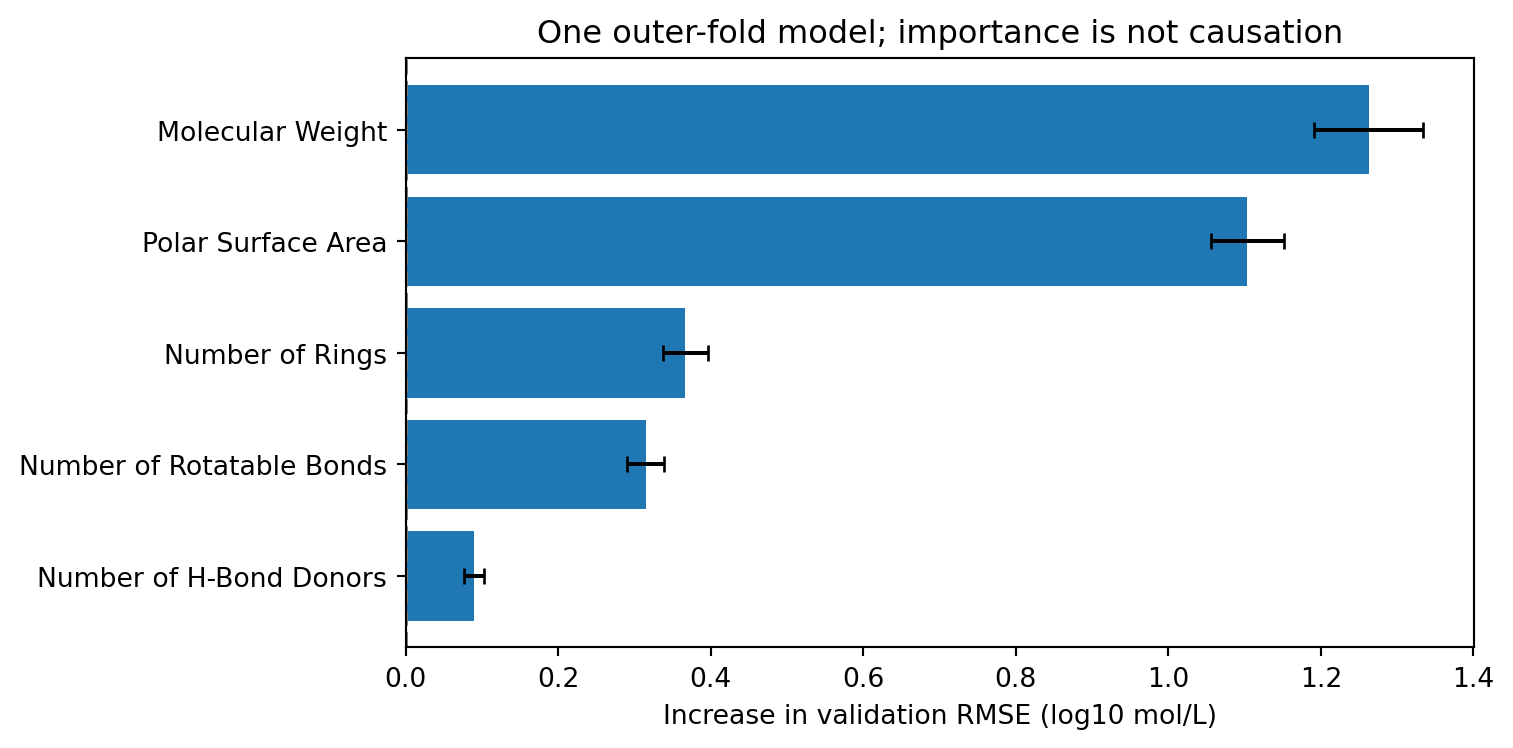

In [13]:
#| fig-alt: "Permutation importance on the first outer validation fold, expressed as an increase in RMSE. Error bars show shuffle variability."
# Task 5b: plot the model's development-fold reliance on each descriptor.
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(np.array(features)[order], importance.importances_mean[order],
        xerr=importance.importances_std[order], capsize=3)
ax.axvline(0, color='0.5', linestyle='--')
ax.set(xlabel='Increase in validation RMSE (log10 mol/L)',
       title='One outer-fold model; importance is not causation')
fig.tight_layout()
plt.show()

In [14]:
assert importance.importances.shape == (len(features), 10), 'Repeat every descriptor shuffle ten times.'
assert set(X_dev.iloc[validation_rows].index).isdisjoint(X_test.index), 'Interpret development data only.'
print('Check passed: importance stays within development data.')

Check passed: importance stays within development data.


## Task 6 — Refit the unchanged search and freeze its winner

Clone `search`, fit it on all development rows and call it `final_search`. Assign `best_model = final_search.best_estimator_`. Record the selected class name and parameters. The final choice comes from the inner CV on all development data, not from comparing test outcomes or selecting the best outer-fold model.

Before continuing, write your selection rule: “Choose the maximum negative-RMSE score among the ten declared configurations, refit on all development rows, then evaluate once.” No tuning step follows Task 7.

In [15]:
# Task 6: choose using development CV and freeze the complete pipeline.
from sklearn.base import clone
final_search = clone(search)
with threadpool_limits(limits=1):
    final_search.fit(X_dev, y_dev)
best_model = final_search.best_estimator_
selected_family = type(best_model.named_steps['model']).__name__
print('Frozen family:', selected_family)
print('Frozen parameters:', final_search.best_params_)
print(f'Selected inner CV RMSE: {-final_search.best_score_:.3f}')

Frozen family: SVR
Frozen parameters: {'model': SVR(), 'model__C': 10, 'model__gamma': 0.3, 'scale': StandardScaler()}
Selected inner CV RMSE: 0.880


In [16]:
assert best_model is final_search.best_estimator_, 'Take the winner from development CV.'
assert hasattr(best_model.named_steps['model'], 'n_features_in_'), 'Refit the selected model.'
print('Check passed: the chosen pipeline is fitted before the final test.')

Check passed: the chosen pipeline is fitted before the final test.


## Task 7 — Open the final test once

Fit the declared mean baseline on all development rows. Make `pred_test` from the frozen pipeline and create `test_results` with test MAE, RMSE and R² for the candidate and baseline. Plot the candidate's measured versus predicted logS.

A disappointing result is a valid result. Report it without switching to a model that looks better on these test labels. Error inspection may generate hypotheses for a future experiment; it does not grant another independent use of the same test set.

In [17]:
# Task 7a: evaluate the frozen candidate and declared baseline once.
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
baseline = DummyRegressor().fit(X_dev, y_dev)
with threadpool_limits(limits=1):
    pred_test = best_model.predict(X_test)
pred_baseline = baseline.predict(X_test)
def metrics(truth, prediction):
    return {'MAE': mean_absolute_error(truth, prediction),
            'RMSE': root_mean_squared_error(truth, prediction),
            'R2': r2_score(truth, prediction)}
test_results = pd.DataFrame({'frozen candidate': metrics(y_test, pred_test),
                             'mean baseline': metrics(y_test, pred_baseline)}).T
test_results.round(3)

,MAE,RMSE,R2
frozen candidate,0.634,0.908,0.826
mean baseline,1.732,2.174,-0.000


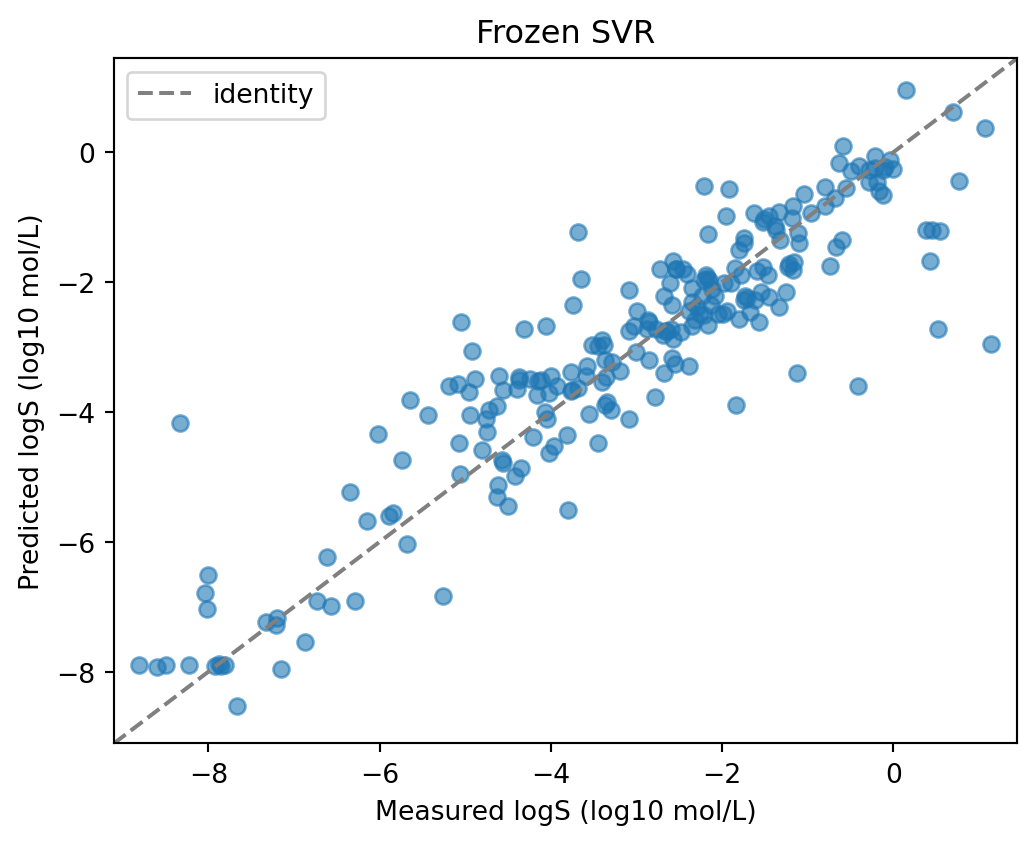

In [18]:
#| fig-alt: "Measured versus predicted test logS for the frozen pipeline, with an identity line indicating perfect agreement."
# Task 7b: plot the candidate selected before the test was opened.
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(y_test, pred_test, alpha=0.6)
limits = [min(y_test.min(), pred_test.min()) - 0.3,
          max(y_test.max(), pred_test.max()) + 0.3]
ax.plot(limits, limits, '--', color='0.5', label='identity')
ax.set(xlabel='Measured logS (log10 mol/L)', ylabel='Predicted logS (log10 mol/L)',
       title=f'Frozen {selected_family}', xlim=limits, ylim=limits)
ax.legend()
fig.tight_layout()
plt.show()

In [19]:
assert len(pred_test) == len(y_test), 'Predict each held-out row.'
assert list(test_results.index) == ['frozen candidate', 'mean baseline'], 'Evaluate the declared comparison.'
assert np.isfinite(test_results.to_numpy()).all(), 'Report finite metrics.'
print('Check passed: final test report is complete.')

Check passed: final test report is complete.


## Task 8 — Write a qualified recommendation

Complete this paragraph with your outputs:

> On five ESOL descriptors, the declared family-and-setting selection procedure achieved a mean outer CV RMSE of [fill in] log10(mol/L), with fold SD [fill in] (a descriptive spread, not a confidence interval), compared with [fill in] for the mean baseline. Refitting the same search on all development data selected [fill in]. Its final test RMSE was [fill in], MAE [fill in] and R² [fill in]. The importance analysis suggests this fold model relied on [fill in], but does not establish causation. I would / would not recommend this procedure for [fill in] because [fill in]. A random split can share related chemistry, so the next independent test should [fill in] .

Also record the library versions, features, seeds, ten candidate configurations and fold design. The model is the complete fitted pipeline, including preprocessing.

**Reflection:** Did outer folds choose the same family? How large was the advantage over the baseline relative to fold-to-fold variation? Would fewer descriptors or a cheaper algorithm be acceptable for the intended use? Which claim needs a scaffold or prospective split?

## Optional extension — PCA plus logistic regression versus a forest

Repeat nested selection on the breast-cancer teaching dataset. Use a stratified 80/20 split, three stratified inner and outer folds, and balanced accuracy. Include PCA dimensions 5 and 15 inside a scaled logistic pipeline and forest leaf sizes 2 and 8 in an unscaled alternative. Keep the final test closed until the search is refitted on all development rows.

This demonstrates a second workflow, not a clinical validation. The label mapping is 0 malignant, 1 benign. Balanced accuracy gives equal weight to class recalls but does not encode the relative costs of mistakes, nor establish probability calibration.

In [20]:
# Optional extension: define a complete classification search.
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
cancer = load_breast_cancer(as_frame=True)
Xc_dev, Xc_test, yc_dev, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.2, stratify=cancer.target, random_state=42)
classifier = Pipeline([('scale', StandardScaler()), ('pca', PCA(svd_solver='full')),
                       ('model', LogisticRegression(max_iter=3000))])
class_grids = [
    {'pca__n_components': [5, 15]},
    {'scale': ['passthrough'], 'pca': ['passthrough'],
     'model': [RandomForestClassifier(n_estimators=60, random_state=42, n_jobs=1)],
     'model__min_samples_leaf': [2, 8]},
]
class_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
class_search = GridSearchCV(classifier, class_grids, scoring='balanced_accuracy', cv=class_cv)
print('Classification configurations:', len(ParameterGrid(class_grids)))

Classification configurations: 4


In [21]:
# Optional extension: assess selection, refit it, then evaluate its frozen winner.
from sklearn.metrics import balanced_accuracy_score
with threadpool_limits(limits=1):
    class_nested = cross_validate(class_search, Xc_dev, yc_dev, cv=class_cv,
                                  scoring='balanced_accuracy')
    class_search.fit(Xc_dev, yc_dev)
    cancer_predictions = class_search.predict(Xc_test)
print('Outer balanced accuracies:', np.round(class_nested['test_score'], 3))
print('Frozen parameters:', class_search.best_params_)
print('Final test balanced accuracy:', round(balanced_accuracy_score(yc_test, cancer_predictions), 3))

Outer balanced accuracies: [0.965 0.967 0.981]
Frozen parameters: {'pca__n_components': 5}
Final test balanced accuracy: 0.955


## Closing reflection

1. Why does putting the family choice in the inner loop matter?
2. Which information would leak if PCA were fitted before cross-validation?
3. Why are a good classification score, calibrated probabilities and a useful decision threshold separate requirements?
4. If you now change a grid after seeing the final results, what evidence would independently evaluate that new procedure?

**Further reading:** [scikit-learn's nested CV example](https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html) and [permutation-importance guide](https://scikit-learn.org/stable/modules/permutation_importance.html).